
---
# Curso: Data Mining - Semana 4

Docente: Soledad Espezúa (s.espezual@up.edu.pe)

---

<a name='manejoarchivos'></a>
# <font color=blue>Laboratorio — EDA II: profundización e interpretación</font>
**Objetivo**: Profundizar el EDA con `kde`, `hue`, visualizaciones categóricas bivariadas y Plotly Express; además, mejorar la presentación de los gráficos y sustentar hallazgos con evidencia.


# <font color=green> Parte 1. Cargar e inspeccionar las fuentes</font>

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

sns.set_theme(style="whitegrid")

df = pd.read_excel("Pinguinos.xlsx")
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

display(df.head())
print("Dimensiones:", df.shape)

# <font color=green>  1. Distribución y densidad</font>

Partimos de una pregunta ya conocida:

**¿Cómo se distribuye el peso corporal?**

Ahora agregaremos `kde=True` y luego separaremos la distribución por especie.

In [ ]:
plt.figure(figsize=(6,3))
sns.histplot(data=df, x="Peso_g", bins=20, kde=True)
plt.title("Distribución del peso corporal")
plt.xlabel("Peso (g)")
plt.ylabel("Frecuencia")
plt.show()

**Interprete:**

- ¿La distribución global parece homogénea?
- ¿Hay más de una zona de concentración?
- ¿Qué podría estar produciendo esa forma?

**Respuesta:**  La distribución global no es completamente homogénea y presenta varias zonas de concentración. Una explicación posible es la mezcla de especies con tamaños corporales diferentes.

In [ ]:
plt.figure(figsize=(6,3))
sns.histplot(
    data=df,
    x="Peso_g",
    hue="Especies",
    kde=True, #agrega una curva de densidad suavizada encima del histograma
    element="step", #histograma se dibuja con contornos escalonados, en vez de barras rellenas.
    stat="density", #cambia el eje Y: en lugar de mostrar conteos(frecuencia), muestra densidad.
    common_norm=False #hace que la normalización se realice por separado para cada especie.
)
#common_norm es importante para que cada distribución se interprete
# por su propia forma y no quede “aplastada” por el tamaño del grupo.

plt.title("Distribución del peso corporal según especie")
plt.xlabel("Peso (g)")
plt.ylabel("Densidad")
plt.show()

**Compare los dos gráficos.** ¿Qué se entiende mejor al separar por especie?

**Respuesta:**  La distribución global no es completamente homogénea y presenta varias zonas de concentración. Una explicación posible es la mezcla de especies con tamaños corporales diferentes.

# <font color=green>  2. EDA categórica × categórica</font>

**Pregunta:** ¿La composición de especies es similar en todas las islas?

Usaremos `countplot()` con `hue`. Además, mostraremos el conteo sobre cada barra.

In [ ]:
plt.figure(figsize=(7,4))
ax = sns.countplot(data=df,
                   x="Isla",
                   hue="Especies" #divide según la variable categórica usando colores distintos.
                   )

#ax.containers-->contiene los grupos de barras
#Recorre todas las barras del gráfico y coloca su valor encima.
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2)

#crea un margen vertical para que las etiquetas no se salgan del gráfico
ax.margins(y=0.15)

plt.title("Composición de especies por isla")
plt.xlabel("Isla")
plt.ylabel("Número de observaciones")
plt.show()

Los conteos permiten comparar cantidades.

Para comparar **composición**, también podemos calcular, qué porcentaje de las observaciones de cada isla corresponde a cada especie.

In [ ]:
#Tabla cruzada
#  filas: Isla;
#  columnas: Especies;
#  celdas: número de pingüinos de cada especie en cada isla
porcentajes = pd.crosstab(
    df["Isla"],
    df["Especies"],
    normalize="index"
) * 100

porcentajes.round(1)

**Hallazgo:**  
**¿Qué diferencia hay entre interpretar conteos e interpretar porcentajes?:**  
**Respuesta:** Los **conteos** muestran la cantidad absoluta de observaciones en cada categoría, mientras que los **porcentajes** muestran la proporción que representa cada categoría dentro de cada grupo. Los porcentajes permiten comparar mejor la composición de grupos que tienen tamaños diferentes.

Por ejemplo, Torgersen tiene menos pingüinos que Biscoe, pero el 100 % de sus observaciones corresponde a Adelie. En Biscoe, en cambio, Gentoo representa el 73.8 % y Adelie el 26.2 %.

# <font color=green>  3. Relación entre variables y uso de `hue`</font>


**Pregunta:** ¿Existe relación entre el largo de las alas y el peso corporal?

Incorporando `Especies` mediante `hue`.

In [ ]:
plt.figure(figsize=(6,3))
sns.scatterplot(
    data=df,
    x="Largo_alas_mm",
    y="Peso_g",
    hue="Especies"
)
plt.title("Largo de alas y peso corporal según especie")
plt.xlabel("Largo de alas (mm)")
plt.ylabel("Peso (g)")
plt.show()

**Compare:**

- dirección de la relación;
- agrupamientos;
- superposición entre especies;
- puntos aislados.

**Hallazgo:**  
**¿Qué información aparece recién con `hue`?:**  
**Respuesta:** la relación global es positiva. Con `hue` aparecen grupos claros: Gentoo se concentra en alas más largas y pesos mayores, mientras Adelie y Chinstrap ocupan zonas menores y parcialmente superpuestas. El gráfico muestra asociación, no causalidad.

#### <font color=green>  Otra vista con mas elementos puede ayudar a mejorar la compresión</font>


Incorporando `Sexo` mediante `style` y `Peso` mediante `size`.



In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df,
                x='Largo_pico_mm',
                y='Alto_pico_mm',
                hue='Especies' ,
                style='Sexo',
                size='Peso_g')
plt.title("Largo de alas y alto del pico según especie")
plt.show()

# <font color=green>   4. Mejorar la presentación de un gráfico</font>

Ejecute primero la versión básica.

In [ ]:
sns.barplot(data=df, x="Especies", y="Peso_g", errorbar=None)
plt.show()

Reproduzca el `gráfico sugerido` que se muestra a continuación. Incluya título, etiquetas de los ejes, unidades y valores sobre las barras.

`Gráfico sugerido`

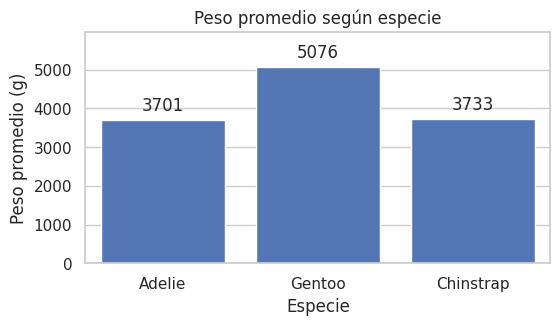

In [ ]:
# Escriba aquí la versión mejorada


# <font color=green>   5. Plotly Express</font>

Usaremos la misma relación largo de alas–peso, pero ahora podremos inspeccionar observaciones individuales.

In [ ]:
fig = px.scatter(
    df,
    x="Largo_alas_mm",
    y="Largo_pico_mm",
    color="Especies",
    symbol="Sexo",
    size="Peso_g",
    size_max=8,
    hover_data=["Sexo", "Isla", "Largo_pico_mm", "Alto_pico_mm"],
    title="Largo de alas y alto del pico según especie"
)
fig.update_traces(
    marker=dict(opacity=0.65)  # Reduce la opacidad
)
fig.show()

Añadir más dimensiones no siempre mejora un gráfico; llega un punto en que lo sobrecarga.

Pruebe:

1. pasar el cursor sobre varios puntos;
2. hacer zoom en una zona;
3. ocultar una especie desde la leyenda.
4. Cambie el marcador:


```
symbol_map={
        "male": "x",
        "female": "diamond"
    },
```
Otros símbolos a probar:
```
"circle"
"square"
"diamond"
"cross"
"x"
"triangle-up"
"triangle-down"
"star"
```



**¿Qué información puede explorar con mayor facilidad que en la figura estática?:**  

# <font color=green> Parte 2. TAREA DE CLASE</font>

A partir del dataset de pingüinos, realice los siguientes análisis. Antes de graficar, construya el subconjunto de datos requerido y verifique cuántas observaciones quedan.

### <font color=blue>1. Comparación entre grupos</font>

Queremos estudiar las diferencias de peso entre especies sin mezclar todas las islas.

Seleccione una isla en la que estén presentes al menos dos especies y:

* filtre únicamente los registros de esa isla;
* elimine para este análisis los registros sin información de Peso_g o Sexo;
* determine cuántas observaciones quedan.

Luego responda:

**¿Cómo se distribuye el peso corporal entre las especies presentes en esa isla?**
**¿Se observan diferencias al considerar el sexo?**
Construya una visualización adecuada.
#### Presente

* Filtro aplicado:
* Número de observaciones resultantes:
* Variables involucradas y tipo:
* Gráfico elegido:
* ¿Por qué es adecuado?:
* Hallazgo sustentado en el gráfico:
* ¿Qué no puede concluirse?:


In [ ]:
# Pregunta 1: comparación entre grupos


### <font color=blue>2. Relación entre variables</font>
En el gráfico realizado en clase observamos una relación global entre características morfológicas. Ahora queremos saber si esa relación se mantiene dentro de una sola especie.

Seleccione una especie y:

* filtre únicamente esa especie;
* conserve registros completos para Largo_alas_mm, Peso_g y Sexo;
* determine cuántas observaciones quedan.

Responda:

**¿Existe una relación entre el largo de las alas y el peso corporal dentro de esa especie? **
**¿El patrón parece similar entre machos y hembras?**

Utilice una visualización que permita distinguir el sexo.

#### Presente

* Filtro aplicado:
* Número de observaciones resultantes:
* Variables involucradas y tipo:
* Gráfico elegido:
* ¿Por qué es adecuado?:
* Hallazgo sustentado en el gráfico:
* ¿Qué no puede concluirse?:


In [ ]:
# Pregunta 2: relación entre variables


### <font color=blue>3. Elección de una visualización</font>
Para uno de los dos análisis anteriores, indique:
**¿Qué otro tipo de gráfico podría parecer una alternativa, pero sería menos adecuado para responder la pregunta?** Explique por qué.


In [ ]:
# Pregunta 3: su elección de visualización
